# Where do Spurs need to recruit?

The current squad is whoever FBref lists at Tottenham in 2026-27, with the minutes they have played so far. Goalkeepers are left out. Quality comes from 2025-26, because most 2026-27 samples are only a handful of matches.

The comparison is the six Premier League clubs with the highest total squad value in 2025-26, Spurs excluded. Those clubs are worked out from the fee data. They are not typed in by hand.

## Six checks, then one score

Each outfield role is compared with the average of those six clubs.

1. **Depth.** How many players have played at least a quarter of the minutes available so far this season. A quarter of a nine-game season is about 200 minutes, not a quarter of 38 games.
2. **Quality.** The model's predicted fee for the two players with the most minutes in the role, averaged. This is what the 2025-26 stats imply, not what the market says. A player needs 900 minutes in 2025-26 to have a prediction. If one of the top two does not, the average uses the one who does, and the table says so.
3. **Output profile.** Four per-90 numbers that describe the role. Spurs' average is weighted by 2026-27 minutes and placed as a percentile among the benchmark players in that role. The rates themselves are from 2025-26, and only from seasons of 900 minutes or more. A percentile of 50 is the middle of that group.
4. **Age.** The share of the role's minutes played by someone aged 30 or older.
5. **Contract.** The share of minutes played by someone whose Transfermarkt contract expires by 30 June 2027. Players with no date on file are left out of both the numerator and the denominator. This file is a July 2026 snapshot, not a live list of deals.
6. **Style.** Which of the 2025-26 style clusters has nobody at Spurs in that role. Style does not go into the score. It says what kind of player would fill the hole.

The need score adds five components. Quality, output, and depth are z-scores across the five roles. Age and contract are the raw minute shares, from 0 to 1, multiplied by 2. A z-score was turning the largest of five tiny shares into a large need. A 4% share now stays near zero. The weights are quality 35%, output 25%, depth 20%, age 10%, contract 10%. A bigger score means Spurs are further behind, or more exposed.

Roles come from Transfermarkt's position. A player with no Transfermarkt match falls back to FBref, and FBref's plain "DF" becomes centre-back.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.needs import WEIGHTS, build_needs

ROLE = {"CB": "Centre-back", "FB": "Full-back", "CM": "Central midfield", "AM_W": "Wide attacker", "ST": "Striker"}
needs, squad = build_needs()
needs["role"] = needs["position_group"].map(ROLE)
clubs = needs["benchmark_clubs"].iloc[0]
display(Markdown(f"**Benchmark clubs, by 2025-26 squad value:** {clubs}."))

table = pd.DataFrame({
    "Role": needs["role"],
    "Need score": needs["need_score"].round(2),
    "Depth": needs.apply(lambda row: f"{int(row.spurs_depth)} vs {row.benchmark_depth:.1f}", axis=1),
    "Quality, €m": needs.apply(
        lambda row: f"{row.spurs_quality / 1e6:.0f} vs {row.benchmark_quality / 1e6:.0f} (n={int(row.spurs_quality_n)})",
        axis=1,
    ),
    "Output percentile": needs["output_percentile"].round(0).astype(int),
    "Age 30+ minutes": (needs["spurs_age_share"] * 100).round(0).astype(int).astype(str) + "%",
    "Contract to Jun 2027": (needs["spurs_contract_share"] * 100).round(0).astype(int).astype(str) + "%",
    "Styles already here": needs["styles_present"].fillna("none"),
    "Styles missing": needs["styles_missing"].fillna("none"),
})
display(table.style.hide(axis="index"))

Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot


**Benchmark clubs, by 2025-26 squad value:** Manchester City, Arsenal, Chelsea, Liverpool, Manchester Utd, Newcastle.

Role,Need score,Depth,"Quality, €m",Output percentile,Age 30+ minutes,Contract to Jun 2027,Styles already here,Styles missing
Striker,0.790000,3 vs 1.3,30 vs 58 (n=1),9,0%,4%,Dropping forward,"Penalty-box striker, Pressing striker"
Full-back,0.310000,2 vs 2.7,23 vs 41 (n=2),53,56%,0%,"Attacking wing-back, Holding fullback, Holding fullback 2",Defensive fullback
Wide attacker,-0.130000,2 vs 4.2,55 vs 53 (n=1),54,0%,0%,Crossing winger,"Foul-drawing winger, Tracking winger, Inside forward"
Central midfield,-0.400000,5 vs 3.3,42 vs 46 (n=2),48,0%,0%,"Arriving midfielder, Ball-winning destroyer, Screening midfielder, Wide midfielder",
Centre-back,-0.450000,2 vs 3.0,43 vs 33 (n=2),52,1%,3%,"Aggressive centre-back, Positional centre-back",Wide centre-back


## Two fixes in this version

Andy Robertson and Sávio were the only 2026-27 Tottenham players with no Transfermarkt id. Robertson is Andrew Robertson (id 234803, born 11 March 1994, left-back). Sávio is Savinho (id 743591, born 10 April 2004, left winger, Manchester City). Both are in `data/manual_overrides.csv`, and the join, the style clusters, and the value model were rerun so the ids carry through. Robertson's 575 minutes now sit at full-back. Sávio's 330 minutes sit with the wide attackers. He played 833 minutes in 2025-26, under the 900-minute line, so he still has no model value and no style label.

Age and contract no longer get z-scored across the five roles. The component is the share of minutes itself, times 2.

## The ranking

A bar to the right is a stronger case for recruiting there.

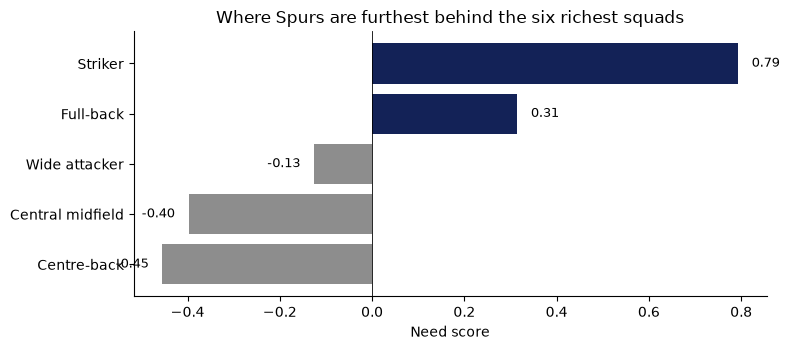

In [2]:
chart = needs.sort_values("need_score", ascending=True)
colors = ["#132257" if score > 0 else "#8d8d8d" for score in chart["need_score"]]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(chart["role"], chart["need_score"], color=colors)
ax.axvline(0, color="black", linewidth=0.6)
for role, score in zip(chart["role"], chart["need_score"]):
    ax.text(score + (0.03 if score >= 0 else -0.03), role, f"{score:.2f}", va="center",
            ha="left" if score >= 0 else "right", fontsize=9)
ax.set_xlabel("Need score")
ax.set_title("Where Spurs are furthest behind the six richest squads")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## Why each role ranks where it does

Quality, output, and depth are z-scores. Age and contract are the minute share times 2, so a small share stays small. Red means that check is pushing the role up the list. Blue means Spurs are in better shape than the other roles on that check. The number under each heading is the weight.

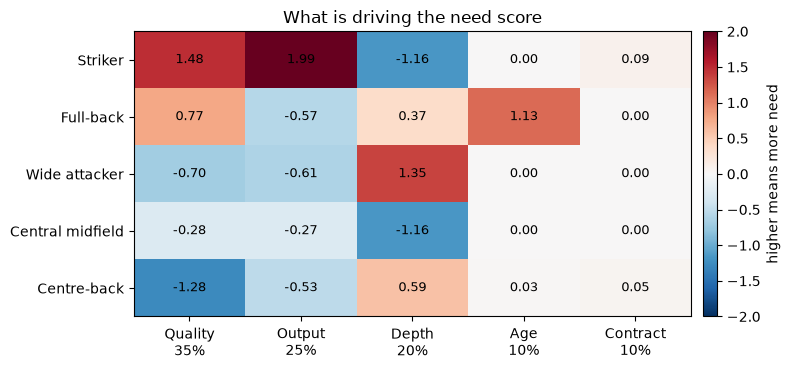

In [3]:
components = [
    ("quality", "Quality"),
    ("output", "Output"),
    ("depth", "Depth"),
    ("age", "Age"),
    ("contract", "Contract"),
]
heat = needs.set_index("role")[[f"z_{name}" for name, _ in components]]
heat.columns = [f"{label}\n{WEIGHTS[name]:.0%}" for name, label in components]
fig, ax = plt.subplots(figsize=(8, 3.8))
image = ax.imshow(heat.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
for row in range(heat.shape[0]):
    for col in range(heat.shape[1]):
        value = heat.to_numpy()[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", color="black", fontsize=9)
ax.set_title("What is driving the need score")
fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02).set_label("higher means more need")
fig.tight_layout()
plt.show()

## Verdict

**Striker — a penalty-box striker.** Solanke, Tel and Richarlison all drop deep. Nobody in the group is a penalty-box striker, and nobody is a pressing striker either. The output profile is still the loudest gap: the minute-weighted 2025-26 rates sit at the 9th percentile for shots, shots on target, goals and non-penalty goals. The model puts Solanke near €30m. The benchmark pair averages about €58m. Marmoush has the most striker minutes this season, but 700 minutes in 2025-26 is under the 900-minute line, so he has no prediction and no style label. Depth is not the problem. Spurs have three strikers over the minutes bar, and the benchmark average is 1.3. The contract share is 4%, Richarlison's deal in the July 2026 snapshot, and that 4% now adds almost nothing to the score.

**Full-back — a defensive full-back.** Porro is an attacking wing-back, Robertson is a holding full-back, and Udogie sits in the quieter holding group. None of them is the defensive full-back, the one who wins more tackles and commits more fouls. Robertson and Porro are the two with a model value, about €23m on average against about €41m for the benchmark pair. Robertson is 32 and has played most of the full-back minutes, so 56% of the group's minutes are aged 30 or older. That share, times 2, is the age component. It is large because the share is large.

Wide attacker drops out of the top two once Sávio's minutes are counted there. Depth is 2 against 4.2, and an inside forward is still the missing style, but Kudus's stats-implied value is now a little above the benchmark pair and the output profile is around the middle. The score is below zero.

Central midfield has every style. Centre-back is the lowest score. Van Hecke and van de Ven still outscore the benchmark pair. The wide centre-back label is empty because that was Robertson, and he is a full-back.

## Does the top two move if the weights change?

Two checks. First, every component at 20%. Second, quality lifted to 50%, with output, depth, age and contract scaled down so they still add up to the other 50%.

In [4]:
def top_two(column):
    return list(needs.sort_values(column, ascending=False)["role"].head(2))

base = top_two("need_score")
equal = top_two("need_score_equal")
half = top_two("need_score_quality50")
lines = [
    f"Main weights: {base[0]} then {base[1]}.",
    f"Equal weights: {equal[0]} then {equal[1]}. The top two "
    + ("stay the same." if set(equal) == set(base) else "change."),
    f"Quality at 50%: {half[0]} then {half[1]}. The top two "
    + ("stay the same." if set(half) == set(base) else "change."),
]
display(Markdown("\n\n".join(lines)))
show = needs[["role", "need_score", "need_score_equal", "need_score_quality50"]].copy()
show.columns = ["Role", "Main score", "Equal weights", "Quality at 50%"]
display(show.round(2).style.hide(axis="index"))

Main weights: Striker then Full-back.

Equal weights: Striker then Full-back. The top two stay the same.

Quality at 50%: Striker then Full-back. The top two stay the same.

Role,Main score,Equal weights,Quality at 50%
Striker,0.790000,0.480000,0.950000
Full-back,0.310000,0.340000,0.420000
Wide attacker,-0.130000,0.010000,-0.260000
Central midfield,-0.400000,-0.340000,-0.370000
Centre-back,-0.450000,-0.230000,-0.640000


## Limitations

There is no injury data. Minutes mix fitness with the manager's choices, so a player on the bench may be a squad option the depth count ignores. The 2026-27 minutes are a partial season, about nine games, and the 25% bar is 25% of that, not of a full campaign.

Quality uses the basic per-90 stats in the value model: shots, tackles, passes of that kind, not chance quality or pressing location. A player under 900 minutes in 2025-26 has no prediction. Marmoush is the important case, and Sávio is the other.

The contract shares use Transfermarkt's July 2026 snapshot. A renewal since then will not be in the file, and about a third of players in that file have no date at all. Those players are left out of the contract share rather than treated as safe or as a risk.

A player who still has no Transfermarkt id would fall back to FBref's broad position, and a plain "DF" would be filed as a centre-back. The 2026-27 Tottenham list has no such player after the two overrides.